#### Importação da base de dados

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("thedevastator/netflix-top-rated-movies-and-tv-shows-2020-2022", 
                                  output_dir="datasets")

print("Path to dataset files:", path)

100%|██████████| 1.81M/1.81M [00:00<00:00, 2.02MB/s]

Extracting files...
Path to dataset files: datasets


#### Leitura dos arquivos .csv para pd.Dataframe

In [6]:
import pandas as pd

df_best_movie_by_year = pd.read_csv("datasets/Best Movie by Year Netflix.csv")

df_best_movies = pd.read_csv("datasets/Best Movies Netflix.csv")

df_best_show_by_year = pd.read_csv("datasets/Best Show by Year Netflix.csv")

df_best_shows = pd.read_csv("datasets/Best Shows Netflix.csv")

#### Q2 - Verificação de valores vazios (pd.Na)

In [16]:
colunas_com_valores_nulos = df_best_movie_by_year.columns[df_best_movie_by_year.isna().any()]
print("Colunas com valores nulos:", colunas_com_valores_nulos)

colunas_com_valores_nulos_best_movies = df_best_movies.columns[df_best_movies.isna().any()]
print("Colunas com valores nulos em df_best_movies:", colunas_com_valores_nulos_best_movies)

colunas_com_valores_nulos_best_show_by_year = df_best_show_by_year.columns[df_best_show_by_year.isna().any()]
print("Colunas com valores nulos em df_best_show_by_year:", colunas_com_valores_nulos_best_show_by_year)

colunas_com_valores_nulos_best_shows = df_best_shows.columns[df_best_shows.isna().any()]
print("Colunas com valores nulos em df_best_shows:", colunas_com_valores_nulos_best_shows)

Colunas com valores nulos: Index([], dtype='str')
Colunas com valores nulos em df_best_movies: Index([], dtype='str')
Colunas com valores nulos em df_best_show_by_year: Index([], dtype='str')
Colunas com valores nulos em df_best_shows: Index([], dtype='str')


#### Q2 - Verificação de valores duplicados

In [37]:
linhas_duplicadas = df_best_movie_by_year.duplicated().any()
print("Linhas duplicadas em df_best_movie_by_year:", linhas_duplicadas)

colunas_com_valores_duplicados = df_best_movie_by_year.columns[
    df_best_movie_by_year.apply(lambda x: x.duplicated()).any()
]
print("Colunas com valores duplicados em df_best_movie_by_year:", colunas_com_valores_duplicados.to_list())

Linhas duplicadas em df_best_movie_by_year: False
Colunas com valores duplicados em df_best_movie_by_year: ['SCORE', 'MAIN_GENRE', 'MAIN_PRODUCTION']


In [38]:
linhas_duplicadas = df_best_movies.duplicated().any()
print("Linhas duplicadas em df_best_movies:", linhas_duplicadas)

colunas_com_valores_duplicados = df_best_movies.columns[
    df_best_movies.apply(lambda x: x.duplicated()).any()
]
print("Colunas com valores duplicados em df_best_movies:", colunas_com_valores_duplicados.to_list())

Linhas duplicadas em df_best_movies: False
Colunas com valores duplicados em df_best_movies: ['RELEASE_YEAR', 'SCORE', 'DURATION', 'MAIN_GENRE', 'MAIN_PRODUCTION']


In [36]:
linhas_duplicadas = df_best_show_by_year.duplicated().any()
print("Linhas duplicadas em df_best_show_by_year:", linhas_duplicadas)

colunas_com_valores_duplicados = df_best_show_by_year.columns[
    df_best_show_by_year.apply(lambda x: x.duplicated()).any()
]
print("Colunas com valores duplicados em df_best_show_by_year:", colunas_com_valores_duplicados.to_list())

Linhas duplicadas em df_best_show_by_year: False
Colunas com valores duplicados em df_best_show_by_year: ['SCORE', 'NUMBER_OF_SEASONS', 'MAIN_GENRE', 'MAIN_PRODUCTION']


In [39]:
linhas_duplicadas = df_best_shows.duplicated().any()
print("Linhas duplicadas em df_best_shows:", linhas_duplicadas)

colunas_com_valores_duplicados = df_best_shows.columns[
    df_best_shows.apply(lambda x: x.duplicated()).any()
]
print("Colunas com valores duplicados em df_best_shows:", colunas_com_valores_duplicados.to_list())

Linhas duplicadas em df_best_shows: False
Colunas com valores duplicados em df_best_shows: ['RELEASE_YEAR', 'SCORE', 'NUMBER_OF_VOTES', 'DURATION', 'NUMBER_OF_SEASONS', 'MAIN_GENRE', 'MAIN_PRODUCTION']


#### Q3 - Estatísticas básicas para os filmes

In [52]:
print("Estatísticas para coluna SCORE")
print(f"Média: {df_best_movies["SCORE"].mean().round(2)}")
print(f"Mediana: {df_best_movies["SCORE"].median()}")
print(f"Moda: {df_best_movies["SCORE"].mode()[0]}")
print(f"Desvio Padrão: {df_best_movies["SCORE"].std().round(2)}\n")

print("Estatísticas para coluna DURATION")
print(f"Média: {df_best_movies["DURATION"].mean().round(2)}")
print(f"Mediana: {df_best_movies["DURATION"].median()}")
print(f"Moda: {df_best_movies["DURATION"].mode()[0]}")
print(f"Desvio Padrão: {df_best_movies["DURATION"].std().round(2)}\n")

print("Estatísticas para coluna NUMBER_OF_VOTES")
print(f"Média: {df_best_movies["NUMBER_OF_VOTES"].mean().round(2)}")
print(f"Mediana: {df_best_movies["NUMBER_OF_VOTES"].median()}")
print(f"Moda: {df_best_movies["NUMBER_OF_VOTES"].mode()[0]}")
print(f"Desvio Padrão: {df_best_movies["NUMBER_OF_VOTES"].std().round(2)}\n")

Estatísticas para coluna SCORE
Média: 7.51
Mediana: 7.4
Moda: 7.1
Desvio Padrão: 0.44

Estatísticas para coluna DURATION
Média: 123.4
Mediana: 122.0
Moda: 104
Desvio Padrão: 28.37

Estatísticas para coluna NUMBER_OF_VOTES
Média: 136520.65
Mediana: 45200.0
Moda: 10139
Desvio Padrão: 234211.42



#### Q3 - Estatísticas básicas para as séries

In [53]:
print("Estatísticas para coluna SCORE")
print(f"Média: {df_best_shows["SCORE"].mean().round(2)}")
print(f"Mediana: {df_best_shows["SCORE"].median()}")
print(f"Moda: {df_best_shows["SCORE"].mode()[0]}")
print(f"Desvio Padrão: {df_best_shows["SCORE"].std().round(2)}\n")

print("Estatísticas para coluna DURATION")
print(f"Média: {df_best_shows["DURATION"].mean().round(2)}")
print(f"Mediana: {df_best_shows["DURATION"].median()}")
print(f"Moda: {df_best_shows["DURATION"].mode()[0]}")
print(f"Desvio Padrão: {df_best_shows["DURATION"].std().round(2)}\n")

print("Estatísticas para coluna NUMBER_OF_VOTES")
print(f"Média: {df_best_shows["NUMBER_OF_VOTES"].mean().round(2)}")
print(f"Mediana: {df_best_shows["NUMBER_OF_VOTES"].median()}")
print(f"Moda: {df_best_shows["NUMBER_OF_VOTES"].mode()[0]}")
print(f"Desvio Padrão: {df_best_shows["NUMBER_OF_VOTES"].std().round(2)}\n")

Estatísticas para coluna SCORE
Média: 8.09
Mediana: 8.0
Moda: 7.5
Desvio Padrão: 0.45

Estatísticas para coluna DURATION
Média: 41.92
Mediana: 44.0
Moda: 25
Desvio Padrão: 15.24

Estatísticas para coluna NUMBER_OF_VOTES
Média: 101966.79
Mediana: 41942.5
Moda: 17992
Desvio Padrão: 168874.64



### Q4 - Gráficos

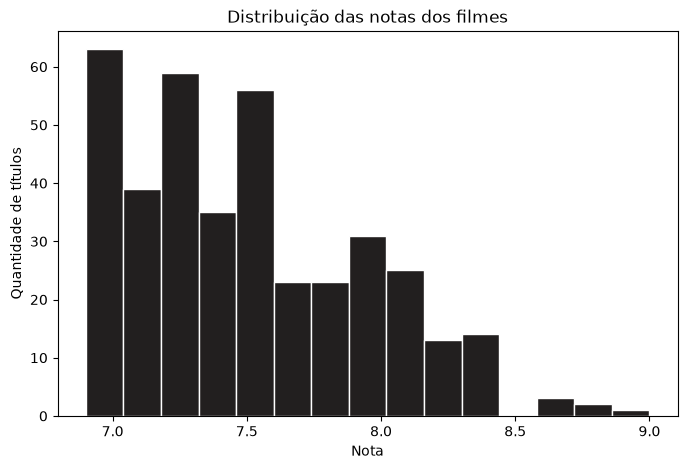

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df_best_movies['SCORE'], bins=15, color='#221F1F', edgecolor='white')
plt.title('Distribuição das notas dos filmes')
plt.xlabel('Nota')
plt.ylabel('Quantidade de títulos')
plt.show()

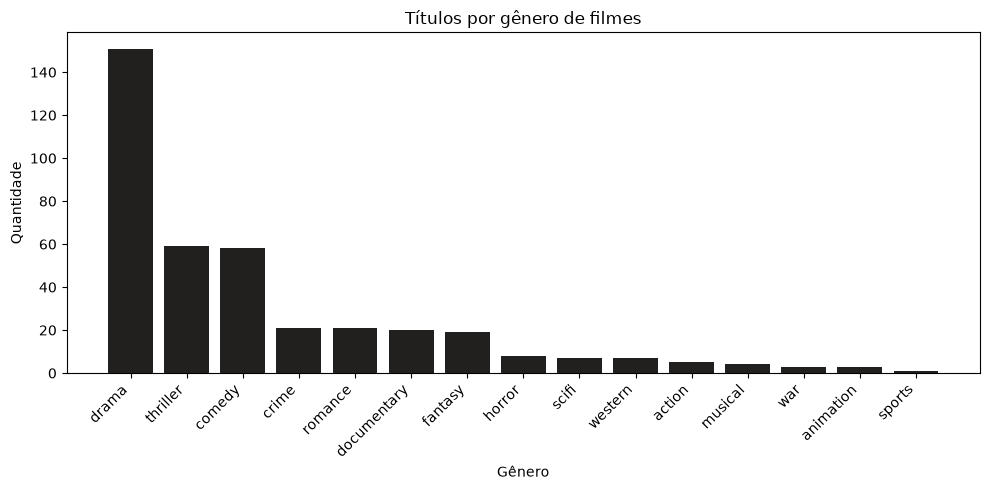

In [82]:
contagem_generos = df_best_movies['MAIN_GENRE'].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(contagem_generos.index, contagem_generos.values, color='#221F1F')
plt.title('Títulos por gênero de filmes')
plt.xlabel('Gênero')
plt.ylabel('Quantidade')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

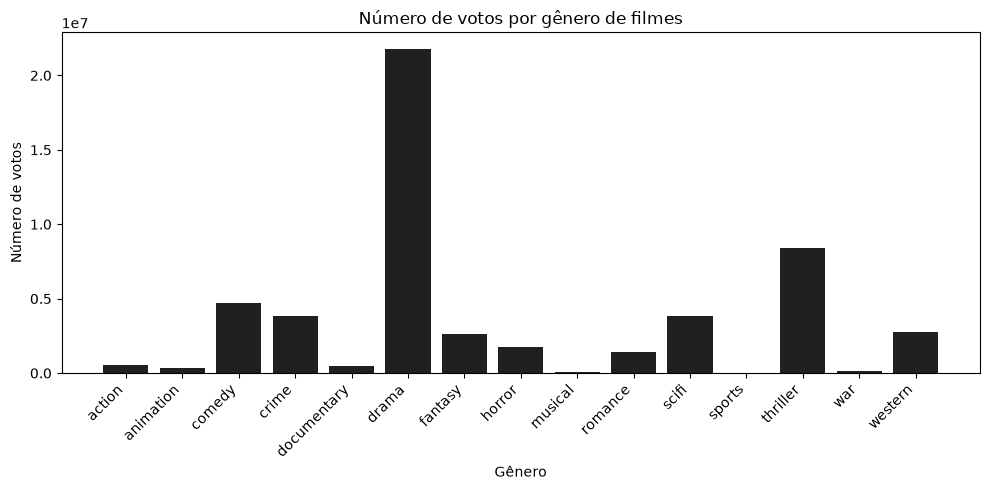

In [85]:
numero_de_votos_por_genero = df_best_movies.groupby('MAIN_GENRE')['NUMBER_OF_VOTES'].sum()

plt.figure(figsize=(10, 5))
plt.bar(numero_de_votos_por_genero.index, numero_de_votos_por_genero.values, color='#221F1F')
plt.title('Número de votos por gênero de filmes')
plt.xlabel('Gênero')
plt.ylabel('Número de votos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

                        TITLE MAIN_GENRE  NUMBER_OF_VOTES
1                   Inception      scifi          2268288
2                Forrest Gump      drama          1994599
6            Django Unchained    western          1472668
5         Saving Private Ryan      drama          1346020
16                Taxi Driver      crime           795222
76         The Imitation Game   thriller           748654
19          Full Metal Jacket      drama           723306
35   How to Train Your Dragon    fantasy           719717
123   Silver Linings Playbook      drama           697481
94         The Social Network      drama           681286


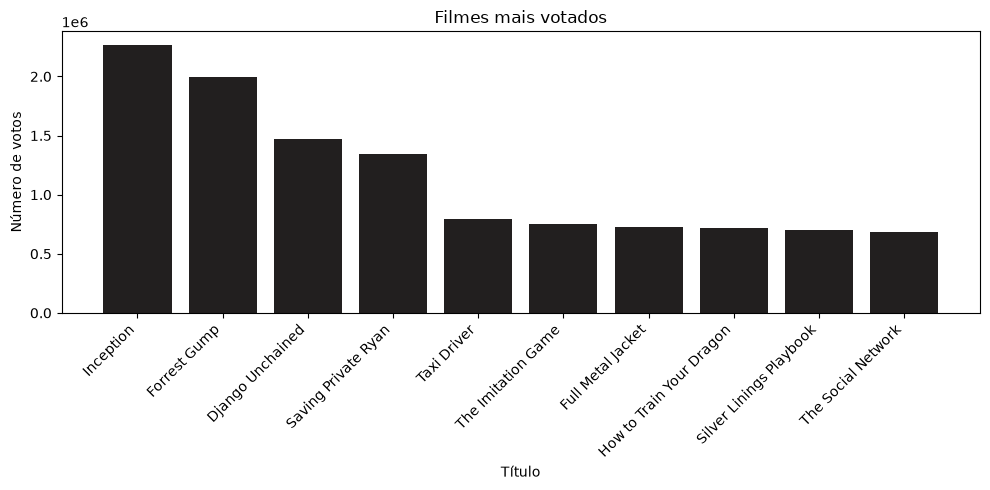

In [88]:
filmes_mais_votados = df_best_movies.sort_values(by='NUMBER_OF_VOTES', ascending=False).head(10)

print(filmes_mais_votados[["TITLE", "MAIN_GENRE", "NUMBER_OF_VOTES"]])

plt.figure(figsize=(10, 5))
plt.bar(filmes_mais_votados['TITLE'], filmes_mais_votados['NUMBER_OF_VOTES'], color='#221F1F')
plt.title('Filmes mais votados')
plt.xlabel('Título')
plt.ylabel('Número de votos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [92]:
df_scifi = df_best_movies[df_best_movies['MAIN_GENRE'] == 'scifi']
print(df_scifi["TITLE"])

1                                           Inception
59                                           G.O.R.A.
67     Neon Genesis Evangelion: The End of Evangelion
75                                  Blade Runner 2049
228                                 Starship Troopers
267                                     Don't Look Up
301                        Black Mirror: Bandersnatch
Name: TITLE, dtype: str


['drama', 'thriller', 'comedy', 'crime', 'romance', 'documentary', 'fantasy', 'horror', 'scifi', 'western']


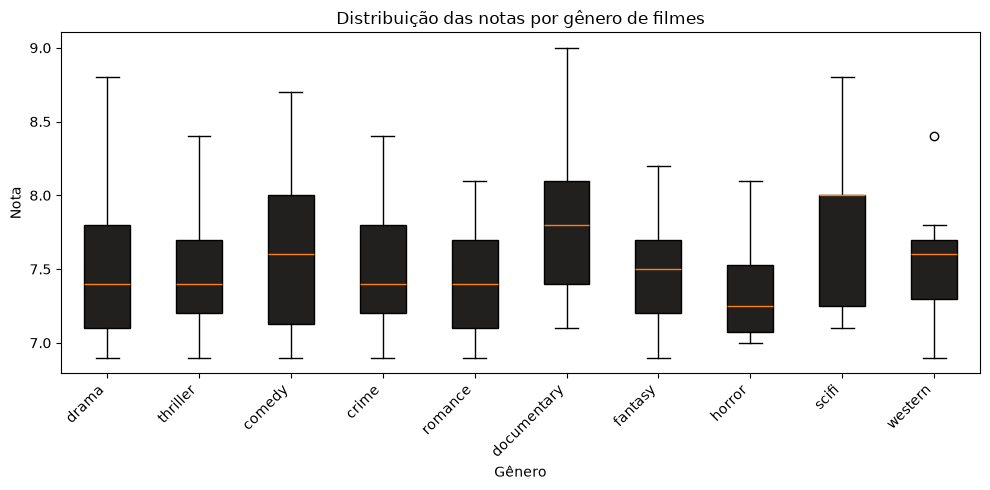

In [79]:
generos = df_best_movies['MAIN_GENRE'].value_counts().head(10).index.tolist()
notas = [df_best_movies.loc[df_best_movies["MAIN_GENRE"] == genero, "SCORE"] for genero in generos]

print(generos)

plt.figure(figsize=(10, 5))
plt.boxplot(notas, tick_labels=generos, patch_artist=True, boxprops=dict(facecolor='#221F1F'))
plt.title('Distribuição das notas por gênero de filmes')
plt.xlabel('Gênero')
plt.ylabel('Nota')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

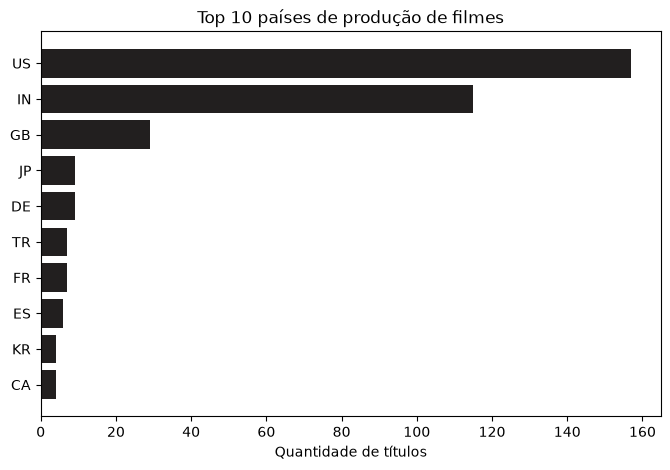

In [64]:
top_paises = df_best_movies['MAIN_PRODUCTION'].value_counts().head(10)

plt.figure(figsize=(8, 5))
plt.barh(top_paises.index[::-1], top_paises.values[::-1], color='#221F1F')
plt.title('Top 10 países de produção de filmes')
plt.xlabel('Quantidade de títulos')
plt.show()

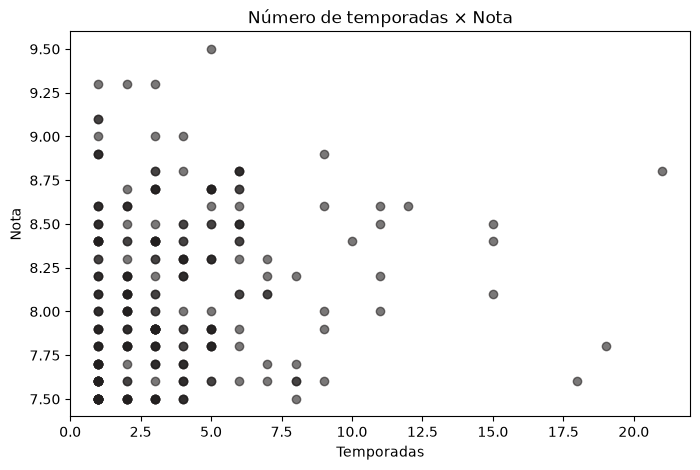

In [68]:
plt.figure(figsize=(8, 5))
plt.scatter(df_best_shows['NUMBER_OF_SEASONS'], df_best_shows['SCORE'], alpha=0.6, color='#221F1F')
plt.title('Número de temporadas × Nota')
plt.xlabel('Temporadas')
plt.ylabel('Nota')
plt.show()

['drama', 'scifi', 'comedy', 'action', 'crime', 'war', 'documentary', 'animation', 'thriller', 'western']


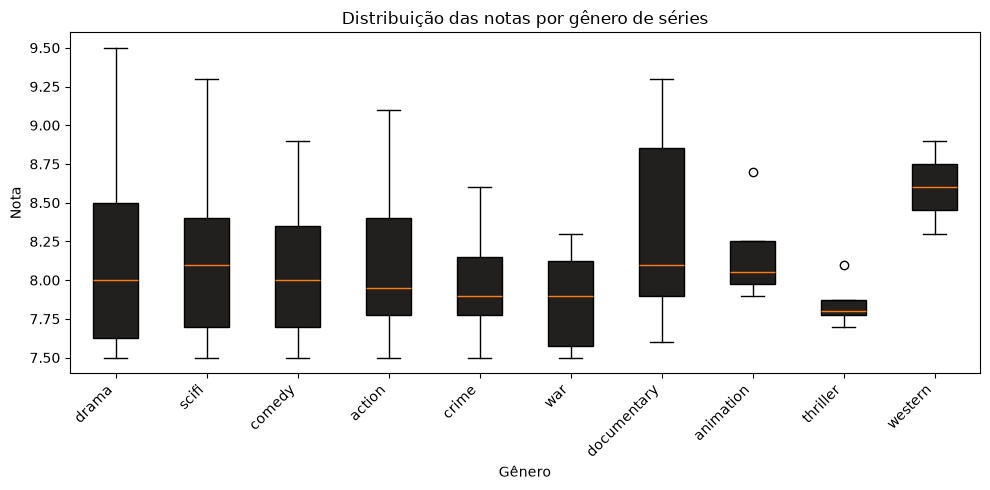

In [81]:
generos = df_best_shows['MAIN_GENRE'].value_counts().head(10).index.tolist()
notas = [df_best_shows.loc[df_best_shows["MAIN_GENRE"] == genero, "SCORE"] for genero in generos]

print(generos)

plt.figure(figsize=(10, 5))
plt.boxplot(notas, tick_labels=generos, patch_artist=True, boxprops=dict(facecolor='#221F1F'))
plt.title('Distribuição das notas por gênero de séries')
plt.xlabel('Gênero')
plt.ylabel('Nota')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()